   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 2.4 MB/s eta 0:00:00

Processing AAPL...

Processing MSFT...

Processing NVDA...

Processing AMZN...

Processing META...

Processing GOOGL...

Processing TSLA...


MULTI-STOCK PERFORMANCE
        Strategy Return  BuyHold Return  Strategy CAGR  BuyHold CAGR  \
Ticker                                                                 
AAPL             0.4719          9.4669         0.0361        0.2405   
MSFT            -0.0940         13.0436        -0.0090        0.2744   
NVDA            -0.6250        403.8218        -0.0861        0.7349   
AMZN             0.2402         12.0212         0.0200        0.2656   
META            -0.5776          7.7564        -0.0761        0.2203   
GOOGL            0.6818         10.7334         0.0489        0.2535   
TSLA             0.0330         32.1326         0.0030        0.3788   

        Strategy Sharpe  BuyHold Sharpe  Strategy MaxDD  BuyHold MaxDD  \
Ticker                        

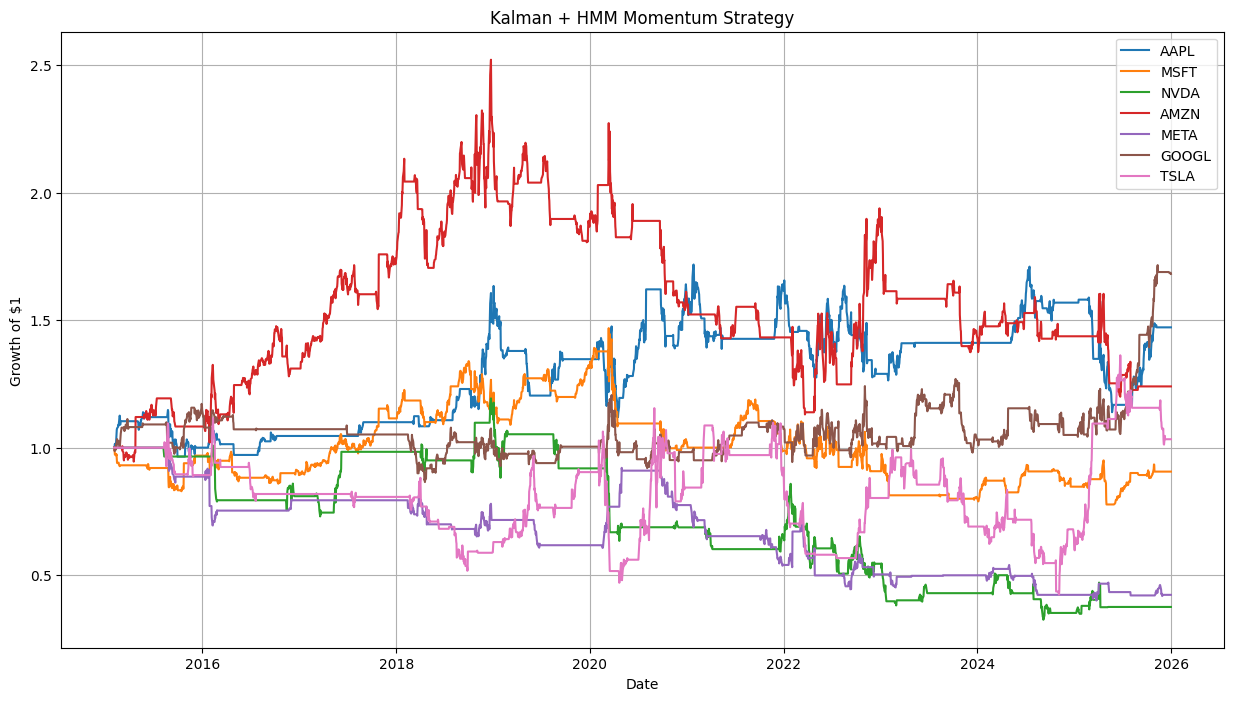

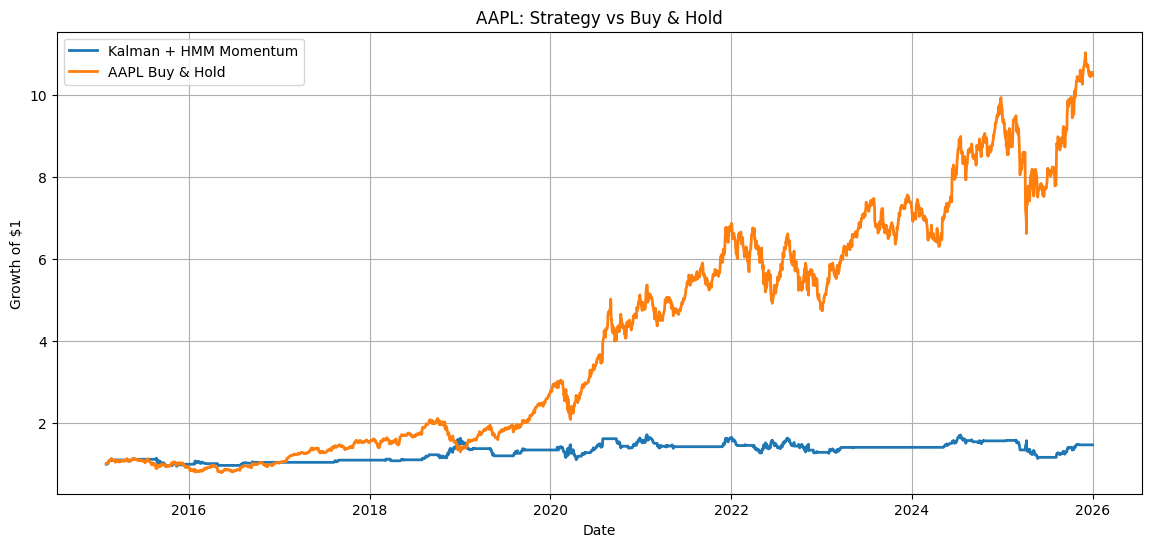

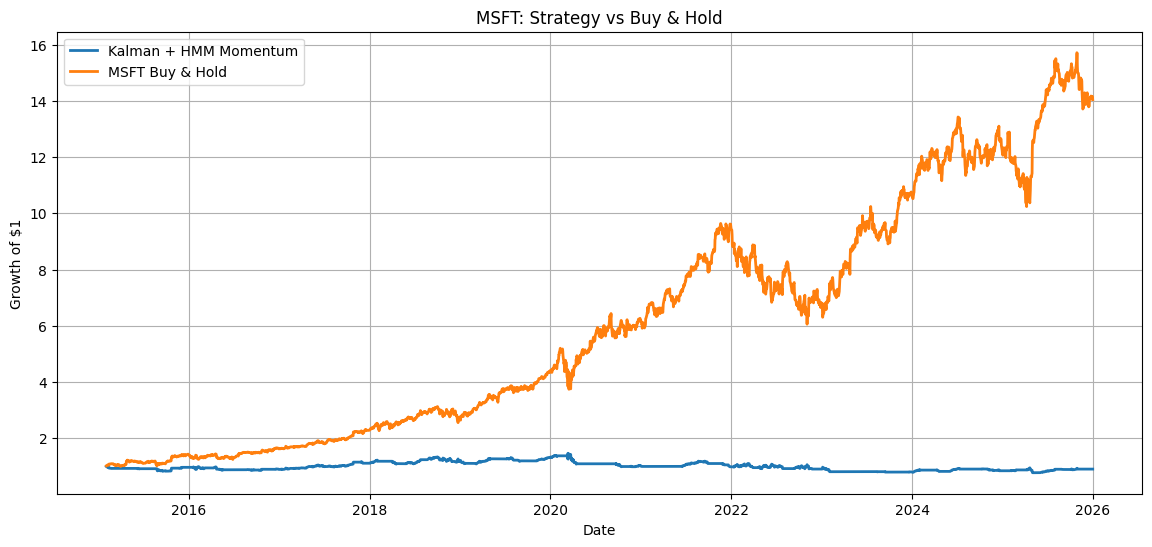

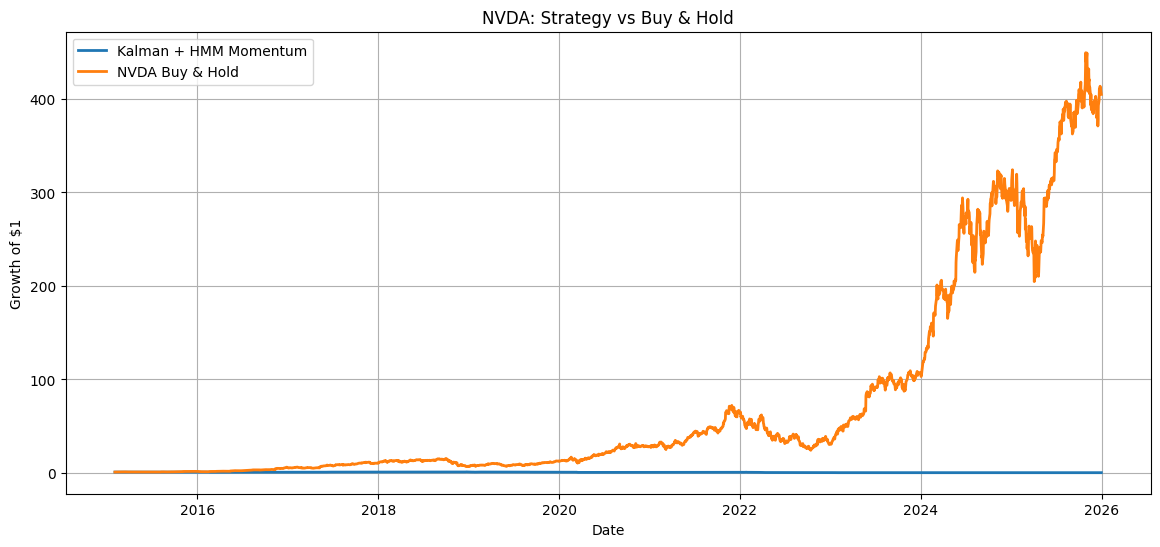

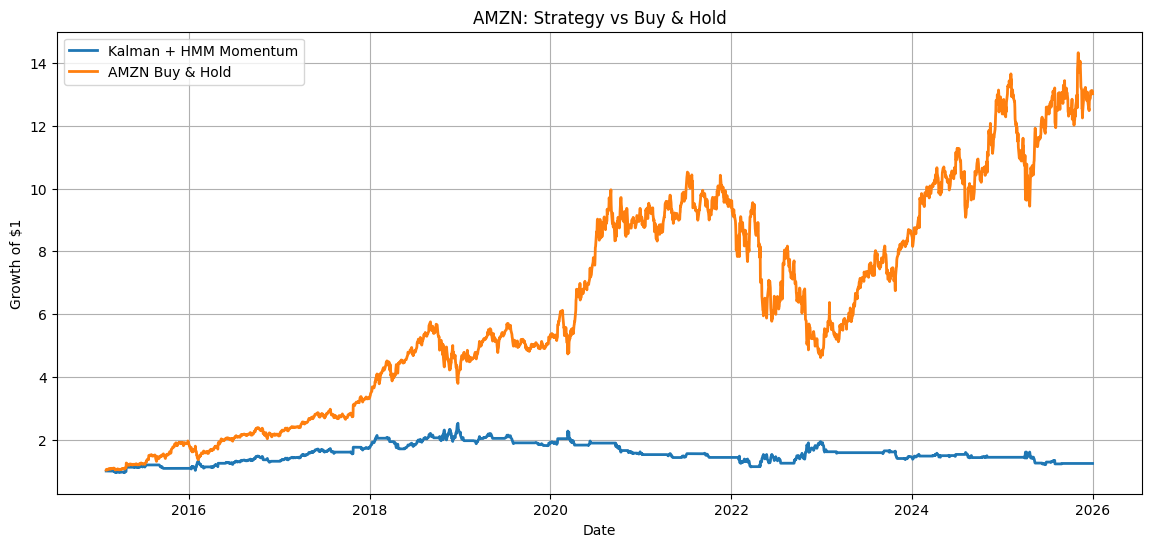

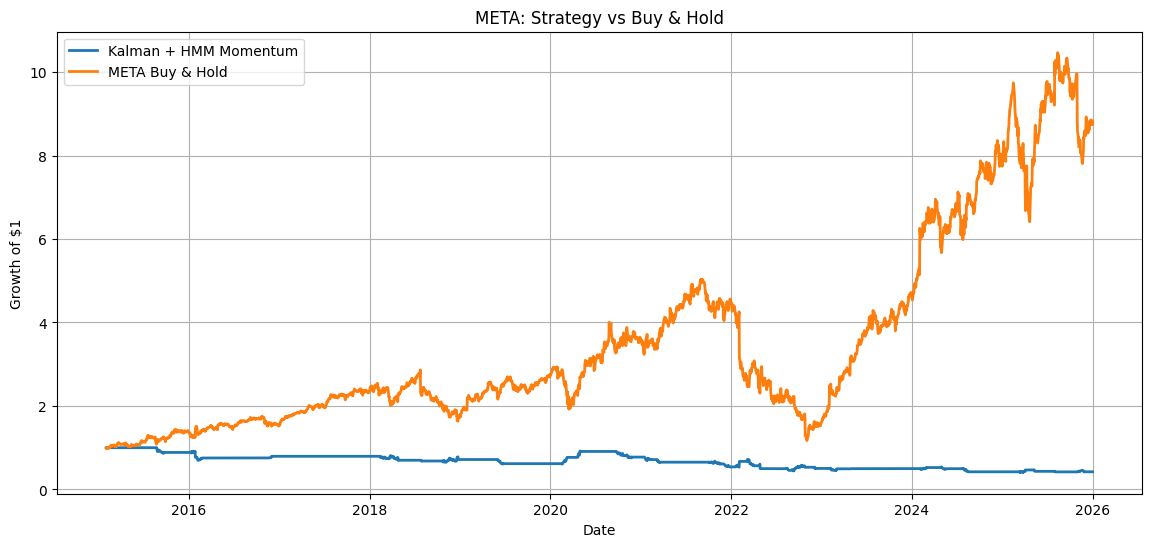

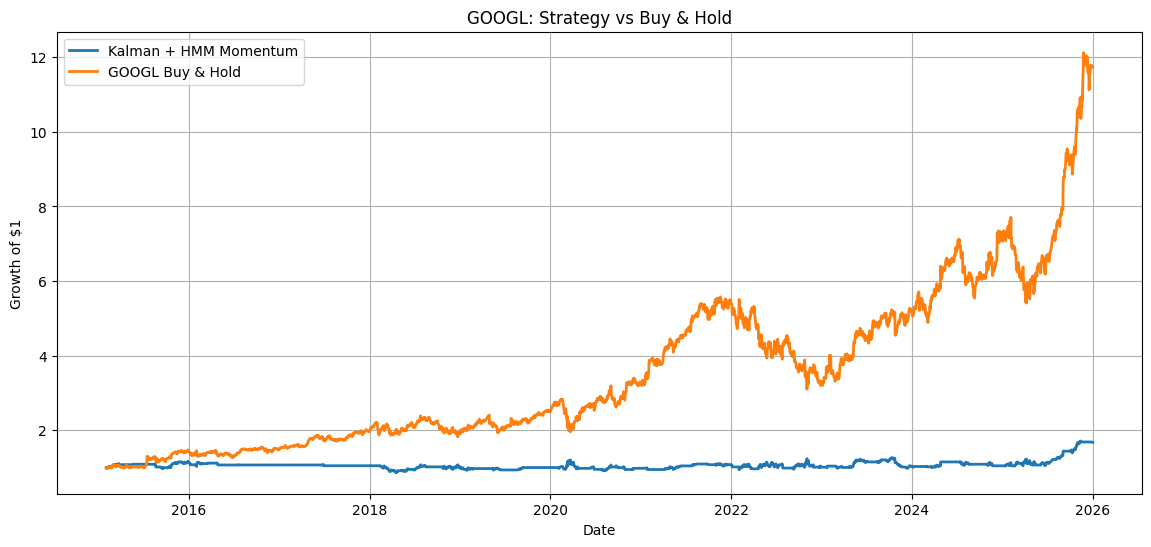

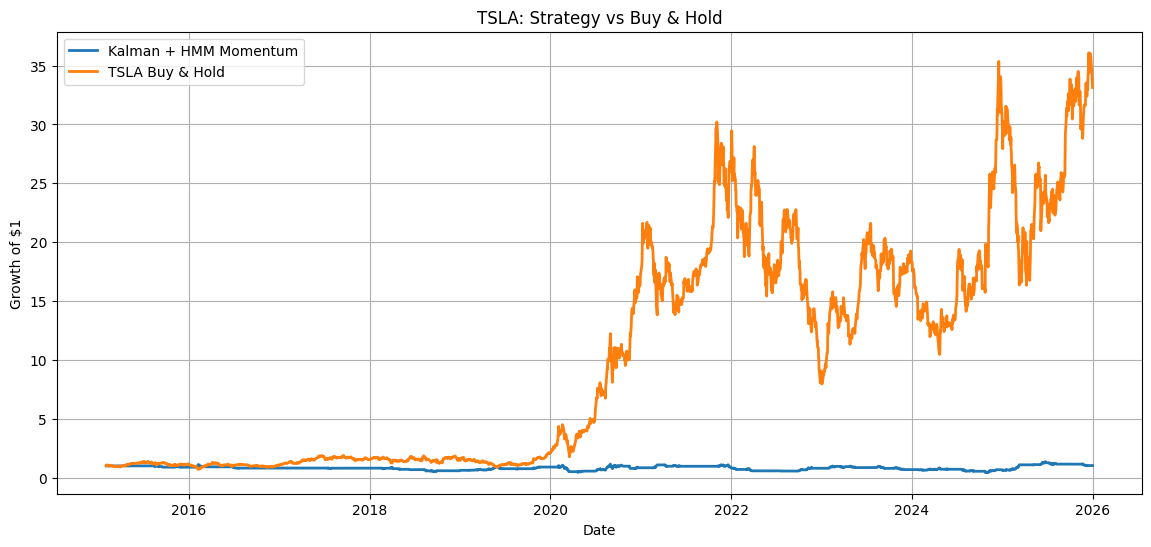

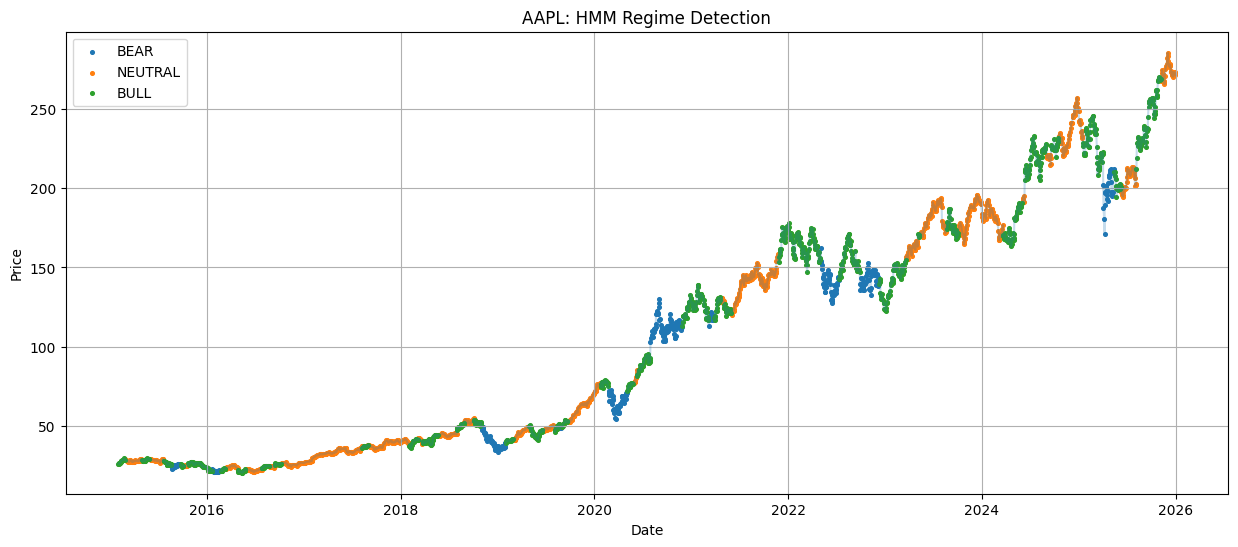

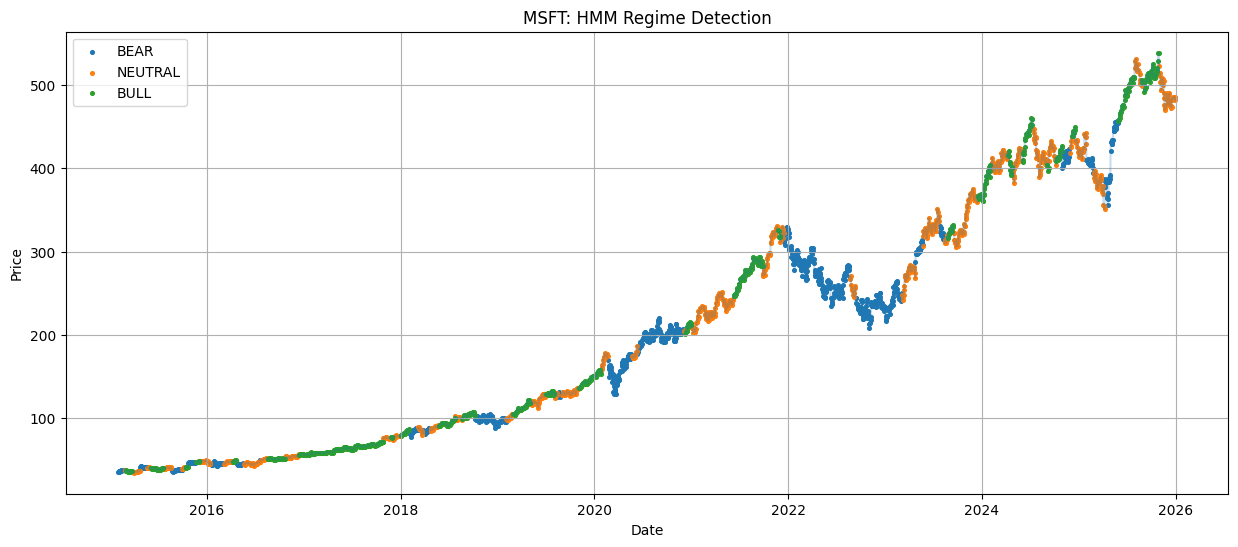

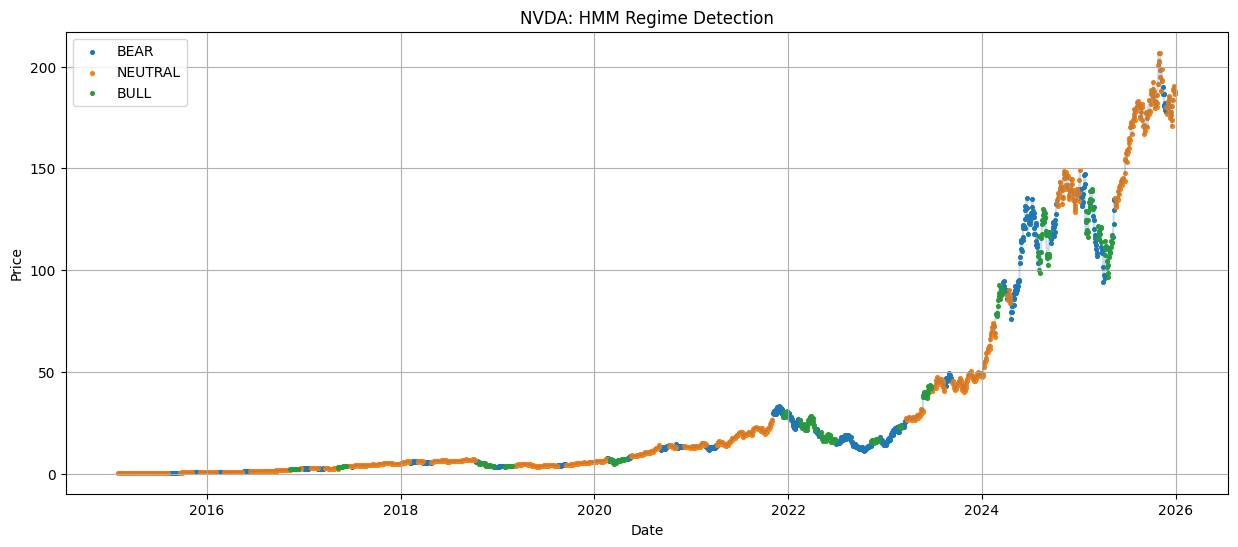

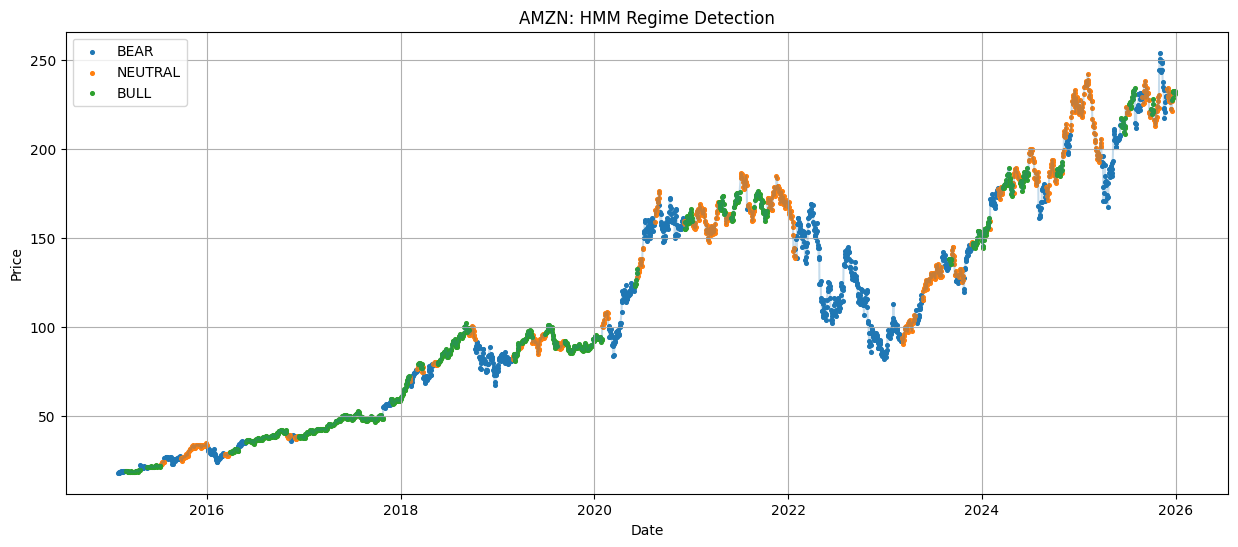

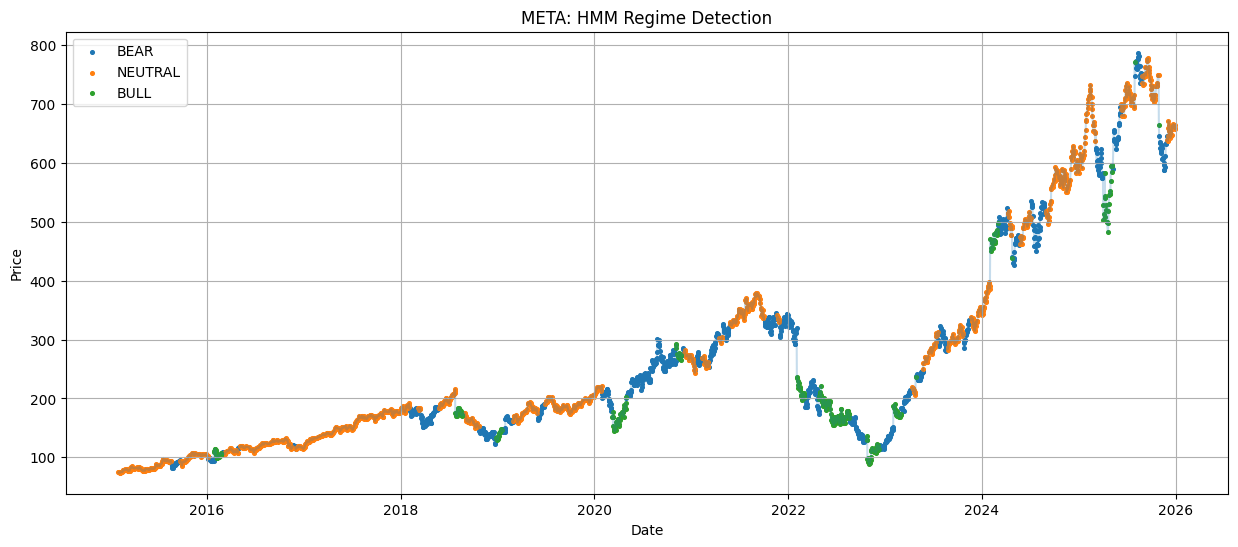

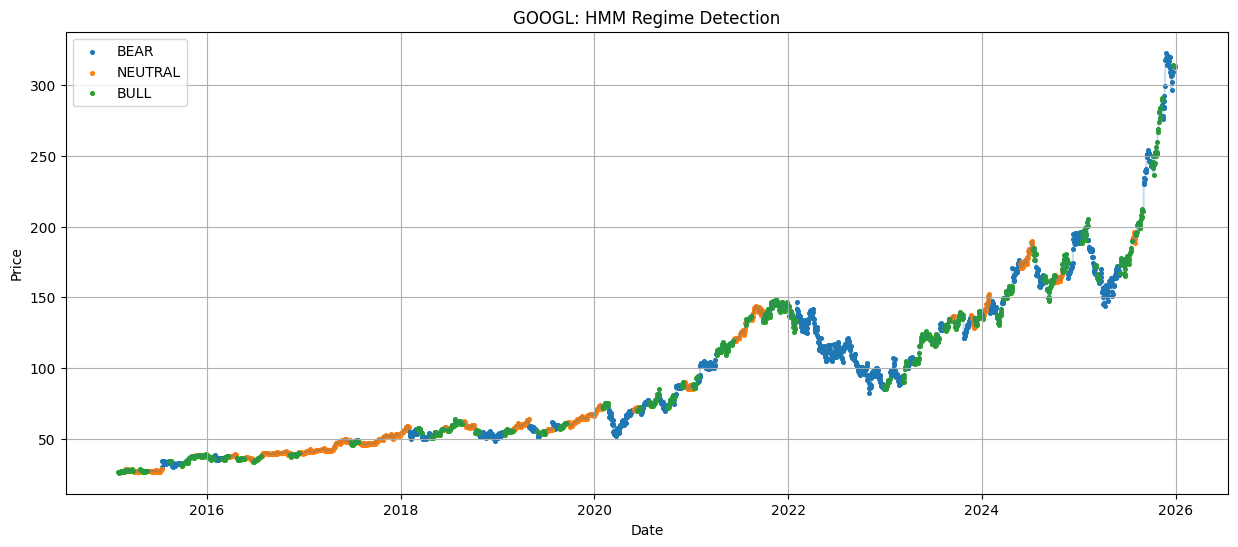

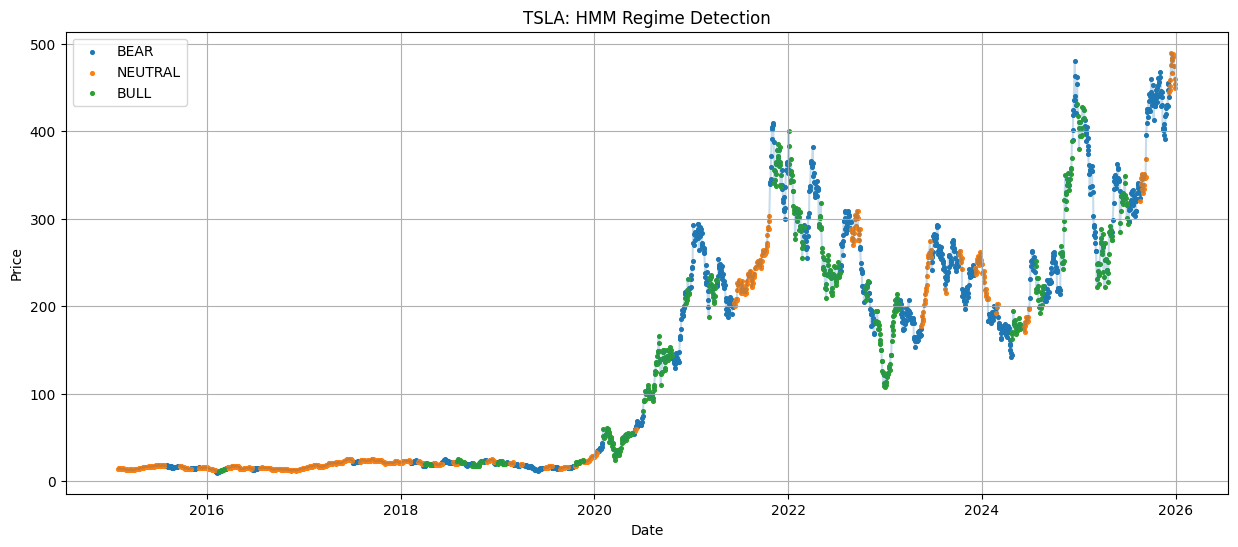



REGIME DISTRIBUTION
        Bear %  Neutral %  Bull %
Ticker                           
AAPL     14.02      46.07   39.91
MSFT     31.39      37.22   31.39
NVDA     26.62      59.50   13.87
AMZN     35.00      29.42   35.58
META     32.88      55.90   11.22
GOOGL    33.65      30.81   35.54
TSLA     39.37      37.25   23.38


Research complete.
Results saved to CSV.


In [1]:
# ============================================================
# KALMAN FILTER + HMM REGIME DETECTION
#              + MOMENTUM STRATEGY
#        MULTI-STOCK REAL MARKET DATA
# ============================================================

!pip -q install yfinance hmmlearn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. PARAMETERS
# ============================================================

TICKERS = [
    "AAPL",
    "MSFT",
    "NVDA",
    "AMZN",
    "META",
    "GOOGL",
    "TSLA"
]

START_DATE = "2015-01-01"
END_DATE   = "2026-01-01"

N_STATES = 3

MOMENTUM_WINDOW = 20

KALMAN_PROCESS_VARIANCE = 1e-5
KALMAN_MEASUREMENT_VARIANCE = 0.001


# ============================================================
# 2. KALMAN FILTER
# ============================================================

def kalman_filter(
    prices,
    process_variance=1e-5,
    measurement_variance=0.001
):

    prices = np.asarray(prices, dtype=float)

    n = len(prices)

    x = np.zeros(n)
    P = np.zeros(n)

    x[0] = prices[0]
    P[0] = 1.0

    for t in range(1, n):

        # Prediction
        x_pred = x[t - 1]

        P_pred = (
            P[t - 1]
            + process_variance
        )

        # Kalman Gain
        K = (
            P_pred /
            (P_pred + measurement_variance)
        )

        # Update
        x[t] = (
            x_pred
            + K * (prices[t] - x_pred)
        )

        P[t] = (
            (1 - K) * P_pred
        )

    return x


# ============================================================
# 3. PERFORMANCE METRICS
# ============================================================

def performance_metrics(returns):

    returns = returns.dropna()

    if len(returns) < 2:
        return {
            "Cumulative Return": np.nan,
            "Annual Return": np.nan,
            "Annual Volatility": np.nan,
            "Sharpe": np.nan,
            "Max Drawdown": np.nan,
            "Win Rate": np.nan
        }

    equity = (
        1 + returns
    ).cumprod()

    cumulative_return = (
        equity.iloc[-1] - 1
    )

    years = (
        len(returns) / 252
    )

    annual_return = (
        equity.iloc[-1]
        ** (1 / years)
        - 1
    )

    annual_volatility = (
        returns.std() *
        np.sqrt(252)
    )

    sharpe = (
        annual_return /
        annual_volatility
        if annual_volatility > 0
        else np.nan
    )

    drawdown = (
        equity /
        equity.cummax()
        - 1
    )

    max_drawdown = drawdown.min()

    win_rate = (
        (returns > 0).mean()
    )

    return {
        "Cumulative Return": cumulative_return,
        "Annual Return": annual_return,
        "Annual Volatility": annual_volatility,
        "Sharpe": sharpe,
        "Max Drawdown": max_drawdown,
        "Win Rate": win_rate
    }


# ============================================================
# 4. DOWNLOAD REAL STOCK DATA
# ============================================================

print("Downloading real market data...")

raw_data = yf.download(
    TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)


# ============================================================
# 5. STORAGE
# ============================================================

results = {}

performance_table = []

regime_tables = {}

transition_tables = {}


# ============================================================
# 6. LOOP THROUGH EACH STOCK
# ============================================================

for ticker in TICKERS:

    print(
        f"\nProcessing {ticker}..."
    )

    # --------------------------------------------------------
    # Extract price
    # --------------------------------------------------------

    if isinstance(
        raw_data.columns,
        pd.MultiIndex
    ):

        close = (
            raw_data["Close"][ticker]
            .dropna()
        )

    else:

        close = (
            raw_data["Close"]
            .dropna()
        )

    df = pd.DataFrame({
        "Close": close
    })

    # --------------------------------------------------------
    # Returns
    # --------------------------------------------------------

    df["Return"] = (
        df["Close"].pct_change()
    )

    df["LogReturn"] = np.log(
        df["Close"] /
        df["Close"].shift(1)
    )

    # --------------------------------------------------------
    # Volatility
    # --------------------------------------------------------

    df["Volatility"] = (
        df["LogReturn"]
        .rolling(20)
        .std()
        * np.sqrt(252)
    )

    # --------------------------------------------------------
    # Kalman Filter
    # --------------------------------------------------------

    df["KalmanPrice"] = kalman_filter(
        df["Close"].values,
        KALMAN_PROCESS_VARIANCE,
        KALMAN_MEASUREMENT_VARIANCE
    )

    # --------------------------------------------------------
    # Kalman Momentum
    # --------------------------------------------------------

    df["KalmanMomentum"] = (
        df["KalmanPrice"]
        .pct_change(MOMENTUM_WINDOW)
    )

    # Kalman slope
    df["KalmanSlope"] = (
        df["KalmanPrice"]
        .diff(5)
    )

    df.dropna(inplace=True)


    # ========================================================
    # 7. HMM FEATURES
    # ========================================================

    features = df[
        [
            "LogReturn",
            "Volatility"
        ]
    ].dropna()


    scaler = StandardScaler()

    X = scaler.fit_transform(
        features
    )


    # ========================================================
    # 8. HMM
    # ========================================================

    hmm = GaussianHMM(
        n_components=N_STATES,
        covariance_type="full",
        n_iter=1000,
        tol=0.001,
        random_state=42
    )

    hmm.fit(X)


    # ========================================================
    # 9. REGIME DETECTION
    # ========================================================

    states = hmm.predict(X)

    features["State"] = states

    df.loc[
        features.index,
        "State"
    ] = states

    df["State"] = (
        df["State"]
        .astype(int)
    )


    # ========================================================
    # 10. IDENTIFY REGIME BEHAVIOUR
    # ========================================================

    regime_stats = (
        df.groupby("State")
        .agg(

            Mean_Return=(
                "Return",
                "mean"
            ),

            Volatility=(
                "Return",
                "std"
            ),

            Kalman_Momentum=(
                "KalmanMomentum",
                "mean"
            ),

            Kalman_Slope=(
                "KalmanSlope",
                "mean"
            ),

            Observations=(
                "Return",
                "count"
            )
        )
    )


    # Sort regimes by return

    sorted_states = (
        regime_stats[
            "Mean_Return"
        ]
        .sort_values()
        .index
    )


    state_mapping = {

        sorted_states[0]:
            "BEAR",

        sorted_states[1]:
            "NEUTRAL",

        sorted_states[2]:
            "BULL"
    }


    df["Regime"] = (
        df["State"]
        .map(state_mapping)
    )


    # ========================================================
    # 11. REGIME STATISTICS
    # ========================================================

    regime_stats["Annual_Return"] = (
        regime_stats["Mean_Return"]
        * 252
    )

    regime_stats["Annual_Volatility"] = (
        regime_stats["Volatility"]
        * np.sqrt(252)
    )


    regime_tables[ticker] = (
        regime_stats
    )


    # ========================================================
    # 12. MOMENTUM SIGNAL
    # ========================================================

    df["Signal"] = 0


    # BULL + positive momentum
    df.loc[
        (
            (df["Regime"] == "BULL") &
            (df["KalmanMomentum"] > 0)
        ),
        "Signal"
    ] = 1


    # BEAR + negative momentum
    df.loc[
        (
            (df["Regime"] == "BEAR") &
            (df["KalmanMomentum"] < 0)
        ),
        "Signal"
    ] = -1


    # NEUTRAL = flat

    df.loc[
        df["Regime"] == "NEUTRAL",
        "Signal"
    ] = 0


    # ========================================================
    # 13. AVOID LOOK-AHEAD
    # ========================================================

    df["Position"] = (
        df["Signal"]
        .shift(1)
    )


    # ========================================================
    # 14. STRATEGY RETURNS
    # ========================================================

    df["StrategyReturn"] = (
        df["Position"]
        * df["Return"]
    )


    df["BuyHoldReturn"] = (
        df["Return"]
    )


    # ========================================================
    # 15. EQUITY CURVES
    # ========================================================

    df["StrategyEquity"] = (
        1 +
        df["StrategyReturn"]
        .fillna(0)
    ).cumprod()


    df["BuyHoldEquity"] = (
        1 +
        df["BuyHoldReturn"]
        .fillna(0)
    ).cumprod()


    # ========================================================
    # 16. PERFORMANCE
    # ========================================================

    strategy_stats = (
        performance_metrics(
            df["StrategyReturn"]
        )
    )

    buyhold_stats = (
        performance_metrics(
            df["BuyHoldReturn"]
        )
    )


    performance_table.append({

        "Ticker": ticker,

        "Strategy Return":
            strategy_stats[
                "Cumulative Return"
            ],

        "BuyHold Return":
            buyhold_stats[
                "Cumulative Return"
            ],

        "Strategy CAGR":
            strategy_stats[
                "Annual Return"
            ],

        "BuyHold CAGR":
            buyhold_stats[
                "Annual Return"
            ],

        "Strategy Sharpe":
            strategy_stats[
                "Sharpe"
            ],

        "BuyHold Sharpe":
            buyhold_stats[
                "Sharpe"
            ],

        "Strategy MaxDD":
            strategy_stats[
                "Max Drawdown"
            ],

        "BuyHold MaxDD":
            buyhold_stats[
                "Max Drawdown"
            ],

        "Strategy WinRate":
            strategy_stats[
                "Win Rate"
            ]
    })


    # ========================================================
    # 17. HMM TRANSITION MATRIX
    # ========================================================

    transition = pd.DataFrame(
        hmm.transmat_
    )

    transition.index = [
        state_mapping[i]
        for i in range(N_STATES)
    ]

    transition.columns = [
        state_mapping[i]
        for i in range(N_STATES)
    ]

    transition_tables[ticker] = (
        transition
    )


    # ========================================================
    # 18. SAVE
    # ========================================================

    results[ticker] = df


# ============================================================
# 19. FINAL PERFORMANCE TABLE
# ============================================================

performance_df = pd.DataFrame(
    performance_table
)

performance_df = (
    performance_df
    .set_index("Ticker")
)


print("\n")
print("=" * 80)
print("MULTI-STOCK PERFORMANCE")
print("=" * 80)

print(
    performance_df.round(4)
)


# ============================================================
# 20. BEST STOCKS BY SHARPE
# ============================================================

print("\n")
print("=" * 80)
print("RANKED BY STRATEGY SHARPE")
print("=" * 80)

print(
    performance_df
    .sort_values(
        "Strategy Sharpe",
        ascending=False
    )
    [["Strategy Sharpe",
      "BuyHold Sharpe",
      "Strategy CAGR",
      "Strategy MaxDD"]]
    .round(4)
)


# ============================================================
# 21. REGIME BEHAVIOUR FOR EVERY STOCK
# ============================================================

for ticker in TICKERS:

    print("\n")
    print("=" * 80)
    print(f"{ticker} - HMM REGIME BEHAVIOUR")
    print("=" * 80)

    table = regime_tables[ticker]

    table_display = table.copy()

    print(
        table_display.round(4)
    )


# ============================================================
# 22. TRANSITION MATRICES
# ============================================================

for ticker in TICKERS:

    print("\n")
    print("=" * 80)
    print(f"{ticker} - HMM TRANSITION MATRIX")
    print("=" * 80)

    print(
        transition_tables[ticker]
        .round(3)
    )


# ============================================================
# 23. PLOT ALL STRATEGY EQUITY CURVES
# ============================================================

plt.figure(figsize=(15, 8))

for ticker in TICKERS:

    df = results[ticker]

    plt.plot(
        df.index,
        df["StrategyEquity"],
        label=ticker
    )

plt.title(
    "Kalman + HMM Momentum Strategy"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 24. STRATEGY VS BUY & HOLD
# ============================================================

for ticker in TICKERS:

    df = results[ticker]

    plt.figure(figsize=(14, 6))

    plt.plot(
        df.index,
        df["StrategyEquity"],
        label="Kalman + HMM Momentum",
        linewidth=2
    )

    plt.plot(
        df.index,
        df["BuyHoldEquity"],
        label=f"{ticker} Buy & Hold",
        linewidth=2
    )

    plt.title(
        f"{ticker}: Strategy vs Buy & Hold"
    )

    plt.xlabel("Date")

    plt.ylabel("Growth of $1")

    plt.legend()

    plt.grid(True)

    plt.show()


# ============================================================
# 25. HMM REGIME MAP
# ============================================================

for ticker in TICKERS:

    df = results[ticker]

    plt.figure(figsize=(15, 6))

    for regime in [
        "BEAR",
        "NEUTRAL",
        "BULL"
    ]:

        subset = df[
            df["Regime"] == regime
        ]

        plt.scatter(
            subset.index,
            subset["Close"],
            s=7,
            label=regime
        )

    plt.plot(
        df.index,
        df["Close"],
        alpha=0.25
    )

    plt.title(
        f"{ticker}: HMM Regime Detection"
    )

    plt.xlabel("Date")

    plt.ylabel("Price")

    plt.legend()

    plt.grid(True)

    plt.show()


# ============================================================
# 26. REGIME DISTRIBUTION
# ============================================================

regime_distribution = []

for ticker in TICKERS:

    df = results[ticker]

    counts = (
        df["Regime"]
        .value_counts(
            normalize=True
        )
        * 100
    )

    regime_distribution.append({

        "Ticker": ticker,

        "Bear %":
            counts.get(
                "BEAR", 0
            ),

        "Neutral %":
            counts.get(
                "NEUTRAL", 0
            ),

        "Bull %":
            counts.get(
                "BULL", 0
            )
    })


regime_distribution_df = (
    pd.DataFrame(
        regime_distribution
    )
    .set_index("Ticker")
)


print("\n")
print("=" * 80)
print("REGIME DISTRIBUTION")
print("=" * 80)

print(
    regime_distribution_df
    .round(2)
)


# ============================================================
# 27. SAVE RESULTS
# ============================================================

performance_df.to_csv(
    "kalman_hmm_momentum_performance.csv"
)

regime_distribution_df.to_csv(
    "hmm_regime_distribution.csv"
)


print("\n")
print("Research complete.")
print("Results saved to CSV.")

In [ ]:
# ============================================================
# WALK-FORWARD KALMAN + HMM MOMENTUM RESEARCH
#
# Models:
# 1. Buy & Hold
# 2. Kalman Momentum
# 3. Kalman + HMM Regime Filter
# 4. Kalman + HMM + Volatility Scaling
#
# Real stocks:
# AAPL, MSFT, NVDA, AMZN, META, GOOGL, TSLA
# ============================================================

!pip -q install yfinance hmmlearn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. PARAMETERS
# ============================================================

TICKERS = [
    "AAPL",
    "MSFT",
    "NVDA",
    "AMZN",
    "META",
    "GOOGL",
    "TSLA"
]

START_DATE = "2015-01-01"
END_DATE = "2026-01-01"

TRAIN_YEARS = 3

MOMENTUM_WINDOW = 20

VOL_WINDOW = 20

N_STATES = 3

# Target annualized volatility
TARGET_VOL = 0.15

# Transaction cost per position change
TRANSACTION_COST = 0.0005


# ============================================================
# 2. KALMAN FILTER
# ============================================================

def kalman_filter(
    prices,
    process_variance=1e-5,
    measurement_variance=0.001
):

    prices = np.asarray(prices, dtype=float)

    n = len(prices)

    x = np.zeros(n)
    P = np.zeros(n)

    x[0] = prices[0]
    P[0] = 1.0

    for t in range(1, n):

        # Prediction
        x_pred = x[t - 1]

        P_pred = (
            P[t - 1]
            + process_variance
        )

        # Kalman gain
        K = (
            P_pred /
            (P_pred + measurement_variance)
        )

        # Update
        x[t] = (
            x_pred
            + K * (prices[t] - x_pred)
        )

        P[t] = (
            (1 - K) * P_pred
        )

    return x


# ============================================================
# 3. DOWNLOAD DATA
# ============================================================

print("Downloading real market data...")

raw = yf.download(
    TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)


# ============================================================
# 4. EXTRACT STOCK DATA
# ============================================================

def get_stock_data(ticker):

    if isinstance(
        raw.columns,
        pd.MultiIndex
    ):

        close = raw["Close"][ticker]

    else:

        close = raw["Close"]

    df = pd.DataFrame({
        "Close": close
    })

    df.dropna(inplace=True)

    df["Return"] = (
        df["Close"].pct_change()
    )

    df["LogReturn"] = np.log(
        df["Close"] /
        df["Close"].shift(1)
    )

    # Realized volatility
    df["Volatility"] = (
        df["LogReturn"]
        .rolling(VOL_WINDOW)
        .std()
        * np.sqrt(252)
    )

    # Kalman filtered price
    df["KalmanPrice"] = kalman_filter(
        df["Close"].values
    )

    # Kalman momentum
    df["KalmanMomentum"] = (
        df["KalmanPrice"]
        .pct_change(MOMENTUM_WINDOW)
    )

    # Kalman slope
    df["KalmanSlope"] = (
        df["KalmanPrice"]
        .diff(5)
    )

    df.dropna(inplace=True)

    return df


# ============================================================
# 5. FIT HMM
# ============================================================

def fit_hmm(train):

    features = train[
        [
            "LogReturn",
            "Volatility"
        ]
    ].dropna()

    scaler = StandardScaler()

    X = scaler.fit_transform(
        features
    )

    model = GaussianHMM(
        n_components=N_STATES,
        covariance_type="full",
        n_iter=500,
        tol=0.001,
        random_state=42
    )

    model.fit(X)

    states = model.predict(X)

    train = train.copy()

    train.loc[
        features.index,
        "State"
    ] = states

    train["State"] = (
        train["State"]
        .astype(int)
    )

    # Determine which HMM state is Bear,
    # Neutral and Bull using training data only.

    state_returns = (
        train
        .groupby("State")["Return"]
        .mean()
    )

    ordered = (
        state_returns
        .sort_values()
        .index
        .tolist()
    )

    mapping = {
        ordered[0]: "BEAR",
        ordered[1]: "NEUTRAL",
        ordered[2]: "BULL"
    }

    return model, scaler, mapping


# ============================================================
# 6. PREDICT REGIME
# ============================================================

def predict_regime(
    model,
    scaler,
    mapping,
    row
):

    X = scaler.transform(
        [[
            row["LogReturn"],
            row["Volatility"]
        ]]
    )

    state = model.predict(X)[0]

    return mapping[state]


# ============================================================
# 7. WALK-FORWARD BACKTEST
# ============================================================

def walk_forward_backtest(df):

    df = df.copy()

    # --------------------------------------------------------
    # Storage
    # --------------------------------------------------------

    df["Regime"] = np.nan

    df["KalmanSignal"] = 0

    df["HMMPosition"] = 0

    df["VolScaledPosition"] = 0

    df["BuyHold"] = df["Return"]


    # --------------------------------------------------------
    # Start after training period
    # --------------------------------------------------------

    train_days = (
        TRAIN_YEARS * 252
    )

    for i in range(
        train_days,
        len(df)
    ):

        # ================================================
        # TRAINING WINDOW
        # ================================================

        train = df.iloc[
            i - train_days:i
        ].copy()


        # ================================================
        # FIT HMM USING ONLY PAST DATA
        # ================================================

        try:

            model, scaler, mapping = (
                fit_hmm(train)
            )

        except Exception:

            continue


        # ================================================
        # CURRENT OBSERVATION
        # ================================================

        current = df.iloc[i]


        # ================================================
        # CURRENT HMM REGIME
        # ================================================

        regime = predict_regime(
            model,
            scaler,
            mapping,
            current
        )

        df.iloc[
            i,
            df.columns.get_loc(
                "Regime"
            )
        ] = regime


        # ================================================
        # MODEL 2
        # KALMAN MOMENTUM
        # ================================================

        momentum = (
            current["KalmanMomentum"]
        )

        if momentum > 0:

            kalman_signal = 1

        elif momentum < 0:

            kalman_signal = -1

        else:

            kalman_signal = 0


        df.iloc[
            i,
            df.columns.get_loc(
                "KalmanSignal"
            )
        ] = kalman_signal


        # ================================================
        # MODEL 3
        # KALMAN + HMM
        # ================================================

        if regime == "BULL":

            hmm_position = (
                1
                if momentum > 0
                else 0
            )

        elif regime == "BEAR":

            hmm_position = (
                -1
                if momentum < 0
                else 0
            )

        else:

            hmm_position = 0


        df.iloc[
            i,
            df.columns.get_loc(
                "HMMPosition"
            )
        ] = hmm_position


        # ================================================
        # MODEL 4
        # VOLATILITY SCALING
        # ================================================

        volatility = (
            current["Volatility"]
        )

        if (
            pd.isna(volatility)
            or volatility <= 0
        ):

            volatility_scale = 0

        else:

            volatility_scale = (
                TARGET_VOL /
                volatility
            )

        # Cap leverage
        volatility_scale = np.clip(
            volatility_scale,
            0,
            2
        )

        scaled_position = (
            hmm_position *
            volatility_scale
        )

        df.iloc[
            i,
            df.columns.get_loc(
                "VolScaledPosition"
            )
        ] = scaled_position


    # ========================================================
    # EXECUTION LAG
    # ========================================================

    df["KalmanPosition"] = (
        df["KalmanSignal"]
        .shift(1)
    )

    df["HMMPositionLag"] = (
        df["HMMPosition"]
        .shift(1)
    )

    df["VolPositionLag"] = (
        df["VolScaledPosition"]
        .shift(1)
    )


    # ========================================================
    # TRANSACTION COSTS
    # ========================================================

    df["KalmanTurnover"] = (
        df["KalmanPosition"]
        .diff()
        .abs()
    )

    df["HMMTurnover"] = (
        df["HMMPositionLag"]
        .diff()
        .abs()
    )

    df["VolTurnover"] = (
        df["VolPositionLag"]
        .diff()
        .abs()
    )


    # ========================================================
    # STRATEGY RETURNS
    # ========================================================

    df["KalmanReturn"] = (
        df["KalmanPosition"]
        * df["Return"]
        -
        df["KalmanTurnover"]
        * TRANSACTION_COST
    )

    df["HMMReturn"] = (
        df["HMMPositionLag"]
        * df["Return"]
        -
        df["HMMTurnover"]
        * TRANSACTION_COST
    )

    df["VolScaledReturn"] = (
        df["VolPositionLag"]
        * df["Return"]
        -
        df["VolTurnover"]
        * TRANSACTION_COST
    )


    # ========================================================
    # EQUITY CURVES
    # ========================================================

    df["BuyHoldEquity"] = (
        1 + df["BuyHold"].fillna(0)
    ).cumprod()

    df["KalmanEquity"] = (
        1 + df["KalmanReturn"].fillna(0)
    ).cumprod()

    df["HMMEquity"] = (
        1 + df["HMMReturn"].fillna(0)
    ).cumprod()

    df["VolScaledEquity"] = (
        1 + df["VolScaledReturn"].fillna(0)
    ).cumprod()


    return df


# ============================================================
# 8. PERFORMANCE METRICS
# ============================================================

def metrics(returns):

    returns = returns.dropna()

    equity = (
        1 + returns
    ).cumprod()

    if len(returns) == 0:

        return {
            "CAGR": np.nan,
            "Volatility": np.nan,
            "Sharpe": np.nan,
            "Sortino": np.nan,
            "Max Drawdown": np.nan,
            "Calmar": np.nan,
            "Win Rate": np.nan
        }

    years = (
        len(returns) / 252
    )

    cagr = (
        equity.iloc[-1]
        ** (1 / years)
        - 1
    )

    volatility = (
        returns.std()
        * np.sqrt(252)
    )

    sharpe = (
        cagr / volatility
        if volatility > 0
        else np.nan
    )

    downside = (
        returns[returns < 0]
        .std()
        * np.sqrt(252)
    )

    sortino = (
        cagr / downside
        if downside > 0
        else np.nan
    )

    drawdown = (
        equity /
        equity.cummax()
        - 1
    )

    max_dd = drawdown.min()

    calmar = (
        cagr / abs(max_dd)
        if max_dd < 0
        else np.nan
    )

    win_rate = (
        returns.gt(0).mean()
    )

    return {

        "CAGR": cagr,

        "Volatility": volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Max Drawdown": max_dd,

        "Calmar": calmar,

        "Win Rate": win_rate
    }


# ============================================================
# 9. RUN ALL STOCKS
# ============================================================

all_results = {}

summary = []

for ticker in TICKERS:

    print(
        f"\nRunning walk-forward test: {ticker}"
    )

    df = get_stock_data(ticker)

    result = walk_forward_backtest(df)

    all_results[ticker] = result

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    bh = metrics(
        result["BuyHold"]
    )

    kalman = metrics(
        result["KalmanReturn"]
    )

    hmm = metrics(
        result["HMMReturn"]
    )

    vol = metrics(
        result["VolScaledReturn"]
    )


    summary.append({

        "Ticker": ticker,

        "BuyHold Sharpe":
            bh["Sharpe"],

        "Kalman Sharpe":
            kalman["Sharpe"],

        "HMM Sharpe":
            hmm["Sharpe"],

        "VolScaled Sharpe":
            vol["Sharpe"],

        "BuyHold CAGR":
            bh["CAGR"],

        "Kalman CAGR":
            kalman["CAGR"],

        "HMM CAGR":
            hmm["CAGR"],

        "VolScaled CAGR":
            vol["CAGR"],

        "BuyHold MaxDD":
            bh["Max Drawdown"],

        "Kalman MaxDD":
            kalman["Max Drawdown"],

        "HMM MaxDD":
            hmm["Max Drawdown"],

        "VolScaled MaxDD":
            vol["Max Drawdown"]
    })


# ============================================================
# 10. COMPARISON TABLE
# ============================================================

comparison = (
    pd.DataFrame(summary)
    .set_index("Ticker")
)

print("\n")
print("=" * 100)
print("WALK-FORWARD PERFORMANCE COMPARISON")
print("=" * 100)

print(
    comparison.round(4)
)


# ============================================================
# 11. SHARPE IMPROVEMENT
# ============================================================

comparison["HMM vs Kalman"] = (
    comparison["HMM Sharpe"]
    -
    comparison["Kalman Sharpe"]
)

comparison["VolScaled vs HMM"] = (
    comparison["VolScaled Sharpe"]
    -
    comparison["HMM Sharpe"]
)

comparison["HMM vs BuyHold"] = (
    comparison["HMM Sharpe"]
    -
    comparison["BuyHold Sharpe"]
)

print("\n")
print("=" * 100)
print("INCREMENTAL VALUE OF HMM")
print("=" * 100)

print(
    comparison[
        [
            "HMM vs Kalman",
            "VolScaled vs HMM",
            "HMM vs BuyHold"
        ]
    ].round(4)
)


# ============================================================
# 12. REGIME BEHAVIOUR
# ============================================================

for ticker in TICKERS:

    df = all_results[ticker]

    regime_data = df.dropna(
        subset=["Regime"]
    )

    print("\n")
    print("=" * 100)
    print(f"{ticker} - OUT-OF-SAMPLE REGIME BEHAVIOUR")
    print("=" * 100)

    regime_stats = (
        regime_data
        .groupby("Regime")
        .agg(

            MeanReturn=(
                "Return",
                "mean"
            ),

            Volatility=(
                "Return",
                "std"
            ),

            KalmanMomentum=(
                "KalmanMomentum",
                "mean"
            ),

            StrategyReturn=(
                "HMMReturn",
                "mean"
            ),

            Observations=(
                "Return",
                "count"
            )
        )
    )

    regime_stats[
        "AnnualReturn"
    ] = (
        regime_stats["MeanReturn"]
        * 252
    )

    regime_stats[
        "AnnualVolatility"
    ] = (
        regime_stats["Volatility"]
        * np.sqrt(252)
    )

    print(
        regime_stats.round(4)
    )


# ============================================================
# 13. EQUITY CURVES
# ============================================================

for ticker in TICKERS:

    df = all_results[ticker]

    plt.figure(figsize=(15, 7))

    plt.plot(
        df.index,
        df["BuyHoldEquity"],
        label="Buy & Hold"
    )

    plt.plot(
        df.index,
        df["KalmanEquity"],
        label="Kalman Momentum"
    )

    plt.plot(
        df.index,
        df["HMMEquity"],
        label="Kalman + HMM"
    )

    plt.plot(
        df.index,
        df["VolScaledEquity"],
        label="Kalman + HMM + Vol Scaling"
    )

    plt.title(
        f"{ticker}: Walk-Forward Strategy Comparison"
    )

    plt.ylabel(
        "Growth of $1"
    )

    plt.xlabel(
        "Date"
    )

    plt.legend()

    plt.grid(True)

    plt.show()


# ============================================================
# 14. HMM REGIME MAP
# ============================================================

for ticker in TICKERS:

    df = all_results[ticker]

    plt.figure(figsize=(15, 6))

    for regime in [
        "BEAR",
        "NEUTRAL",
        "BULL"
    ]:

        subset = df[
            df["Regime"] == regime
        ]

        plt.scatter(
            subset.index,
            subset["Close"],
            s=8,
            label=regime
        )

    plt.plot(
        df.index,
        df["Close"],
        alpha=0.25
    )

    plt.title(
        f"{ticker}: Walk-Forward HMM Regimes"
    )

    plt.xlabel("Date")

    plt.ylabel("Price")

    plt.legend()

    plt.grid(True)

    plt.show()


# ============================================================
# 15. REGIME DISTRIBUTION
# ============================================================

regime_distribution = []

for ticker in TICKERS:

    df = all_results[ticker]

    dist = (
        df["Regime"]
        .value_counts(
            normalize=True
        )
        * 100
    )

    regime_distribution.append({

        "Ticker": ticker,

        "Bear %":
            dist.get("BEAR", 0),

        "Neutral %":
            dist.get("NEUTRAL", 0),

        "Bull %":
            dist.get("BULL", 0)
    })


regime_distribution = (
    pd.DataFrame(
        regime_distribution
    )
    .set_index("Ticker")
)


print("\n")
print("=" * 100)
print("OUT-OF-SAMPLE REGIME DISTRIBUTION")
print("=" * 100)

print(
    regime_distribution.round(2)
)


# ============================================================
# 16. TURNOVER
# ============================================================

turnover_table = []

for ticker in TICKERS:

    df = all_results[ticker]

    turnover_table.append({

        "Ticker": ticker,

        "Kalman Turnover":
            df["KalmanTurnover"]
            .sum(),

        "HMM Turnover":
            df["HMMTurnover"]
            .sum(),

        "VolScaled Turnover":
            df["VolTurnover"]
            .sum()
    })


turnover_table = (
    pd.DataFrame(
        turnover_table
    )
    .set_index("Ticker")
)


print("\n")
print("=" * 100)
print("TURNOVER")
print("=" * 100)

print(
    turnover_table.round(2)
)


# ============================================================
# 17. SAVE RESULTS
# ============================================================

comparison.to_csv(
    "walk_forward_strategy_comparison.csv"
)

regime_distribution.to_csv(
    "walk_forward_regime_distribution.csv"
)

turnover_table.to_csv(
    "strategy_turnover.csv"
)


print("\n")
print("=" * 100)
print("RESEARCH COMPLETE")
print("=" * 100)

print(
    "\nFiles saved:"
)

print(
    "1. walk_forward_strategy_comparison.csv"
)

print(
    "2. walk_forward_regime_distribution.csv"
)

print(
    "3. strategy_turnover.csv"
)


Running walk-forward test: AAPL
